In [1]:
import sys
from pathlib import Path
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import seaborn as sns

ROOT = Path.cwd()

FITS_DIR = ROOT / "fits_files"
FIGS_DIR = ROOT / "figures"
FIGS_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "py_modules"))

import results_comp
import fit_fraction_latex_tools as ffa

ffa = importlib.reload(ffa)

sns.set_context("talk")


Configuration

In [39]:
# Complete Lfrac sample available on disk
ALL_FIT_LIMITS = (0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9 , 1.0)

# Fractions adopted for subsequent analysis.
# Change this whenever desired.
SELECTED_FIT_LIMITS = (0.4, 0.5, 0.6)

DATASET_CONFIGS = [
    {
        "group": "MUSE",
        "dataset_prefix": "MUSE-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),
        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },
]

Preview the expected files

In [40]:
samples = ffa.build_fraction_sample_grid(
    DATASET_CONFIGS,
    ALL_FIT_LIMITS,
)

sample_table = pd.DataFrame(samples)[
    ["group", "bin", "line", "fit_limit", "file_name"]
]

display(sample_table)

,group,bin,line,fit_limit,file_name
0,MUSE,0,H,0.2,MUSE-30Dor-H-bin0_02
1,MUSE,0,H,0.3,MUSE-30Dor-H-bin0_03
2,MUSE,0,H,0.4,MUSE-30Dor-H-bin0_04
3,MUSE,0,H,0.5,MUSE-30Dor-H-bin0_05
4,MUSE,0,H,0.6,MUSE-30Dor-H-bin0_06
5,MUSE,0,H,0.7,MUSE-30Dor-H-bin0_07
6,MUSE,0,H,0.8,MUSE-30Dor-H-bin0_08
7,MUSE,0,H,0.9,MUSE-30Dor-H-bin0_09
8,MUSE,0,H,1.0,MUSE-30Dor-H-bin0_10


Load the complete \(L_{\rm frac}\)

In [41]:
all_fraction_results, failures = (
    ffa.load_multi_line_bin_fraction_results(
        results_comp,
        FITS_DIR,
        dataset_configs=DATASET_CONFIGS,
        fit_limits=ALL_FIT_LIMITS,
        read_header=True,
        on_error="warn",
        return_failures=True,
    )
)

print(f"Loaded: {len(all_fraction_results)}")
print(f"Unavailable: {len(failures)}")

if failures:
    display(
        pd.DataFrame(failures)[
            ["file_name", "error"]
        ]
    )

Loaded: 9
Unavailable: 0


Convert the complete sample to a tidy table

In [42]:
fraction_table = ffa.results_to_dataframe(
    all_fraction_results
)

display(fraction_table)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE,0,H,0.2,None,None,sig2,210.543238,17.264807,55.109408,193.278431,265.652646,None
1,MUSE,0,H,0.2,None,None,r0,2.276951,0.252627,0.948468,2.024325,3.225420,None
2,MUSE,0,H,0.2,None,None,m,1.068738,0.144998,0.068789,0.923740,1.137527,None
3,MUSE,0,H,0.2,None,None,noise,5.104529,0.589824,0.592156,4.514705,5.696685,None
4,MUSE,0,H,0.2,None,None,s0,0.079662,0.021701,0.043032,0.057960,0.122693,None
5,MUSE,0,H,0.3,None,None,sig2,216.645164,11.358515,19.624796,205.286648,236.269960,None
6,MUSE,0,H,0.3,None,None,r0,2.370214,0.175962,0.326142,2.194253,2.696356,None
7,MUSE,0,H,0.3,None,None,m,1.050101,0.076692,0.053180,0.973409,1.103282,None
8,MUSE,0,H,0.3,None,None,noise,5.142094,0.494262,0.495277,4.647832,5.637372,None
9,MUSE,0,H,0.3,None,None,s0,0.084343,0.018292,0.026192,0.066051,0.110535,None


Section 3 — inspect the complete \(L_{\rm frac}\) sample

In [43]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [pc]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

sig2: negative lower uncertainty at Lfrac = [0.6] -> lower limit set to zero
r0: negative lower uncertainty at Lfrac = [0.6] -> lower limit set to zero


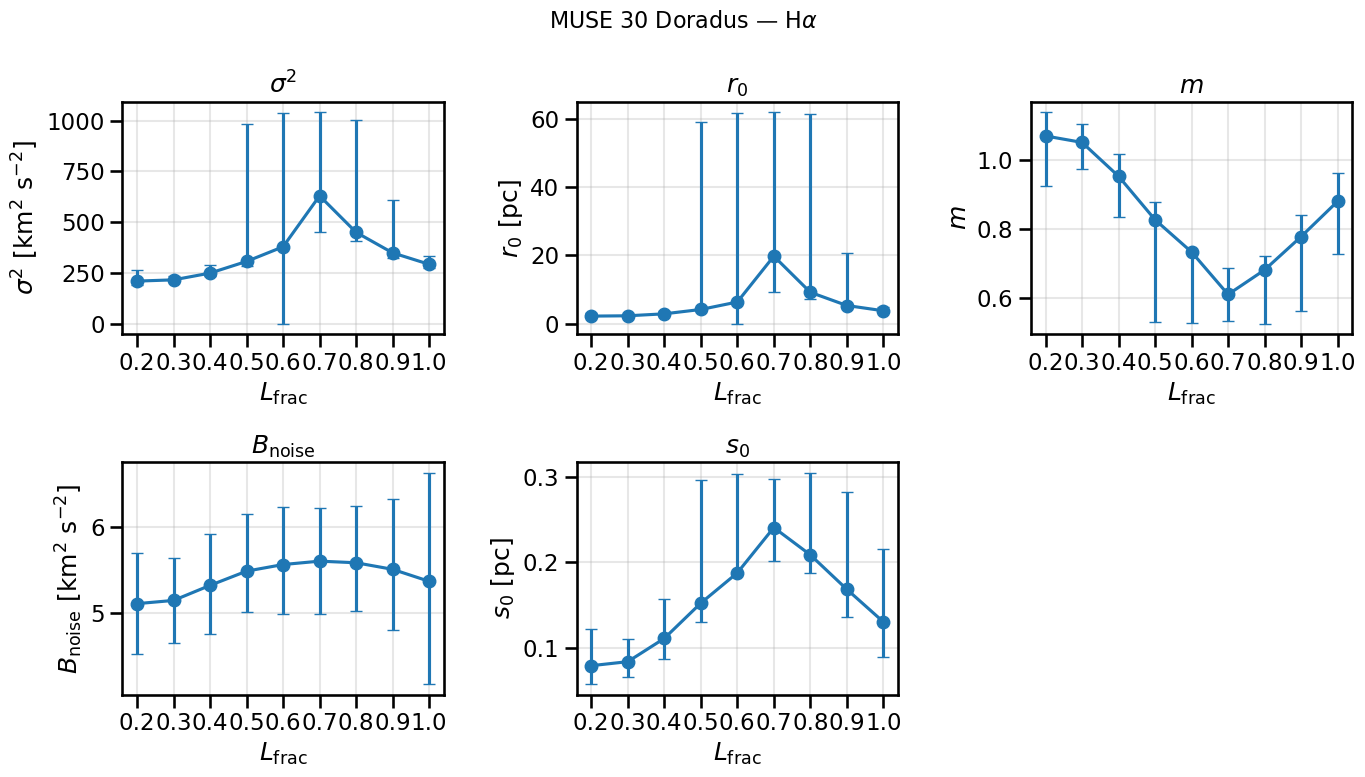

In [71]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8),
)

axes = axes.ravel()

for ax, param in zip(axes, PARAMETERS):

    df_param = (
        fraction_table[
            fraction_table["parameter"] == param
        ]
        .sort_values("fit_limit")
    )

    x = df_param["fit_limit"].to_numpy()
    y = df_param["value"].to_numpy(dtype=float)

    err_lower = df_param["err_lower"].to_numpy(dtype=float)
    err_upper = df_param["err_upper"].to_numpy(dtype=float)

    # --------------------------------------------------
    # Lower uncertainty
    #
    # If the stored lower uncertainty is negative,
    # interpret it as reaching the physical boundary
    # at zero. Therefore the lower error magnitude
    # becomes equal to the central value.
    # --------------------------------------------------
    bad_lower = err_lower < 0

    if np.any(bad_lower):
        print(
            f"{param}: negative lower uncertainty at Lfrac = "
            f"{df_param.loc[bad_lower, 'fit_limit'].tolist()} "
            "-> lower limit set to zero"
        )

    err_lower_plot = np.where(
        bad_lower,
        y,
        np.abs(err_lower),
    )

    # Upper errors only need to be positive magnitudes
    err_upper_plot = np.abs(err_upper)

    yerr = np.vstack([
        err_lower_plot,
        err_upper_plot,
    ])

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------
    ax.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        linestyle="-",
        capsize=4,
    )

    ax.set_title(PARAM_TITLES[param])
    ax.set_xlabel(r"$L_{\rm frac}$")
    ax.set_ylabel(PARAM_LABELS[param])

    ax.set_xticks(ALL_FIT_LIMITS)
    ax.grid(alpha=0.3)

axes[-1].axis("off")

fig.suptitle(
    r"MUSE 30 Doradus — H$\alpha$",
    fontsize=16,
)

fig.tight_layout()

plt.show()

Visually indicate the fractions selected for the final result

In [45]:
SELECTED_FIT_LIMITS = (0.2, 0.3, 0.4)

In [46]:
selected_min = min(SELECTED_FIT_LIMITS)
selected_max = max(SELECTED_FIT_LIMITS)

In [47]:
ax.axvspan(
    selected_min,
    selected_max,
    alpha=0.10,
)

In [48]:
selected_mask = df_param["fit_limit"].isin(
    SELECTED_FIT_LIMITS
)

ax.scatter(
    df_param.loc[selected_mask, "fit_limit"],
    df_param.loc[selected_mask, "value"],
    s=90,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=5,
)

Downstream selection and averaging

In [49]:
FIT_LIMITS_BY_GROUP = {
    "MUSE": SELECTED_FIT_LIMITS,
}

In [50]:
selected_results_pc = (
    ffa.select_or_average_fit_results(
        all_fraction_results,
        fit_limits_by_group=FIT_LIMITS_BY_GROUP,
        group_keys=("group", "bin", "line"),
    )
)

In [51]:
selected_table_pc = ffa.results_to_dataframe(
    selected_results_pc
)

display(selected_table_pc)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,sig2,225.710123,32.431691,65.061026,193.278431,290.771149,3
1,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,r0,2.529723,0.505398,1.287584,2.024325,3.817306,3
2,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,m,1.023771,0.189899,0.113757,0.833872,1.137527,3
3,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,noise,5.188290,0.673585,0.731041,4.514705,5.919331,3
4,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,s0,0.091828,0.033868,0.065546,0.057960,0.157374,3


In [52]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [pc]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

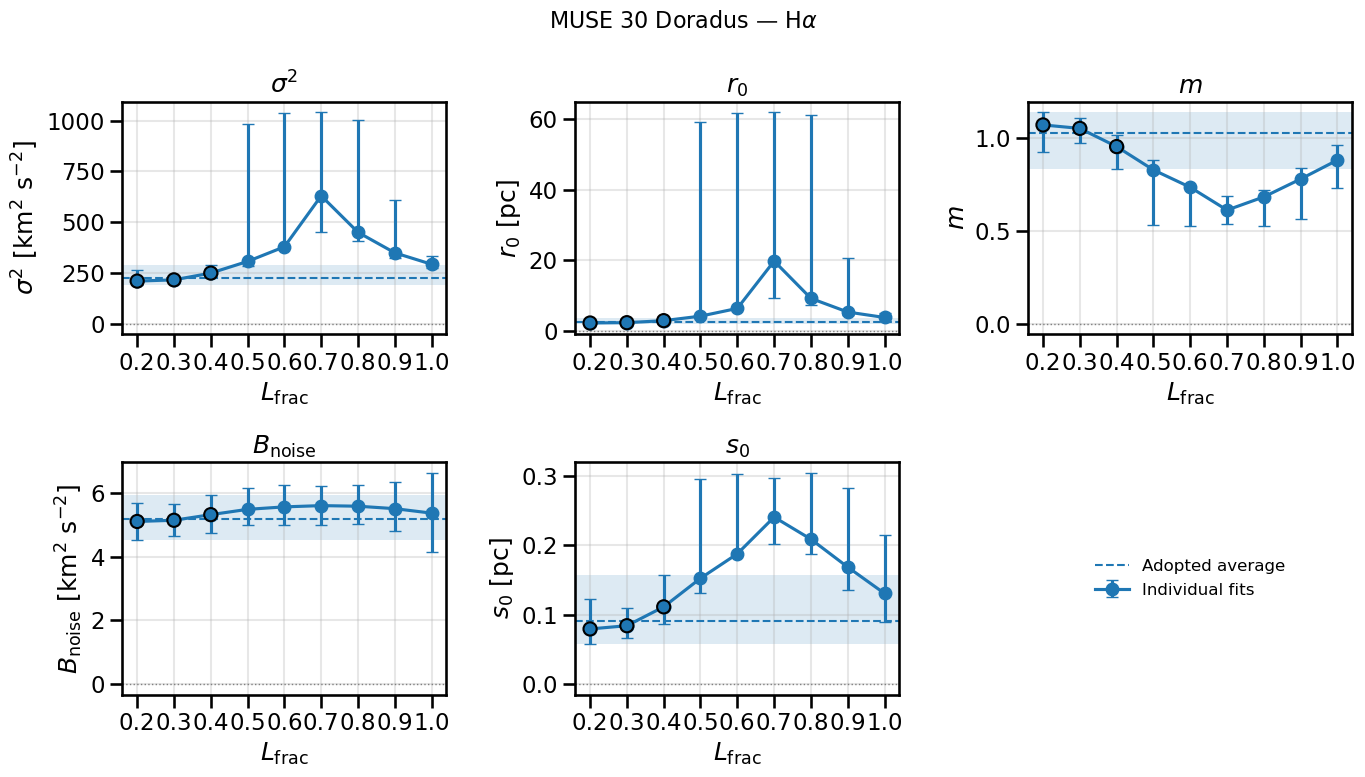

In [66]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8),
)

axes = axes.ravel()

for ax, param in zip(axes, PARAMETERS):

    # --------------------------------------------------
    # Complete Lfrac sample
    # --------------------------------------------------
    df_raw = (
        fraction_table[
            fraction_table["parameter"] == param
        ]
        .sort_values("fit_limit")
    )

    x = df_raw["fit_limit"].to_numpy()
    y = df_raw["value"].to_numpy()

    err_lower = df_raw["err_lower"].to_numpy(dtype=float)
    err_upper = df_raw["err_upper"].to_numpy(dtype=float)

    # Matplotlib requires positive error magnitudes
    yerr = np.vstack([
        np.abs(err_lower),
        np.abs(err_upper),
    ])

    ax.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        linestyle="-",
        capsize=4,
        label="Individual fits",
    )

    # --------------------------------------------------
    # Selected / averaged result
    # --------------------------------------------------
    df_avg = selected_table_pc[
        selected_table_pc["parameter"] == param
    ]

    if len(df_avg) == 1:

        avg = df_avg["value"].iloc[0]
        avg_lower = df_avg["err_lower"].iloc[0]
        avg_upper = df_avg["err_upper"].iloc[0]

        lower_limit = avg - avg_lower
        upper_limit = avg + avg_upper

        # Mean value
        ax.axhline(
            avg,
            linestyle="--",
            linewidth=1.5,
            label="Adopted average",
        )

        # Full uncertainty envelope
        ax.axhspan(
            lower_limit,
            upper_limit,
            alpha=0.15,
        )

    # --------------------------------------------------
    # Mark selected Lfrac values
    # --------------------------------------------------
    selected_mask = df_raw["fit_limit"].isin(
        SELECTED_FIT_LIMITS
    )

    ax.scatter(
        df_raw.loc[selected_mask, "fit_limit"],
        df_raw.loc[selected_mask, "value"],
        s=90,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        zorder=5,
    )

    ax.axhline(
        0.0,
        color="0.5",
        linestyle=":",
        linewidth=1.0,
    )

    ax.set_title(PARAM_TITLES[param])
    ax.set_xlabel(r"$L_{\rm frac}$")
    ax.set_ylabel(PARAM_LABELS[param])

    ax.set_xticks(ALL_FIT_LIMITS)
    ax.grid(alpha=0.3)

axes[-1].axis("off")

handles, labels = axes[0].get_legend_handles_labels()

axes[-1].legend(
    handles,
    labels,
    loc="center",
    frameon=False,
    fontsize=12,
)

fig.suptitle(
    r"MUSE 30 Doradus — H$\alpha$",
    fontsize=16,
)

fig.tight_layout()


fig.savefig(
    FIGS_DIR / "MUSE_30Dor_H_Lfrac_diagnostics.jpg",
    bbox_inches="tight",
)
plt.show()

In [54]:
adopted_table = (
    selected_table_pc[
        ["parameter", "value", "err_lower", "err_upper"]
    ]
    .copy()
)

display(adopted_table)

,parameter,value,err_lower,err_upper
0,sig2,225.710123,32.431691,65.061026
1,r0,2.529723,0.505398,1.287584
2,m,1.023771,0.189899,0.113757
3,noise,5.188290,0.673585,0.731041
4,s0,0.091828,0.033868,0.065546


In [55]:
selected_results = ffa.convert_s0_pc_to_arcsec(
    selected_results_pc,
    fwhm_factor=2.355,
    copy=True,
)

selected_table = ffa.results_to_dataframe(
    selected_results
)

display(selected_table)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,sig2,225.710123,32.431691,65.061026,193.278431,290.771149,3
1,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,r0,2.529723,0.505398,1.287584,2.024325,3.817306,3
2,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,m,1.023771,0.189899,0.113757,0.833872,1.137527,3
3,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,noise,5.188290,0.673585,0.731041,4.514705,5.919331,3
4,MUSE,0,H,None,"(0.2, 0.3, 0.4)",average,s0,0.892114,0.329026,0.636786,0.563088,1.528900,3


In [56]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS_FINAL = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

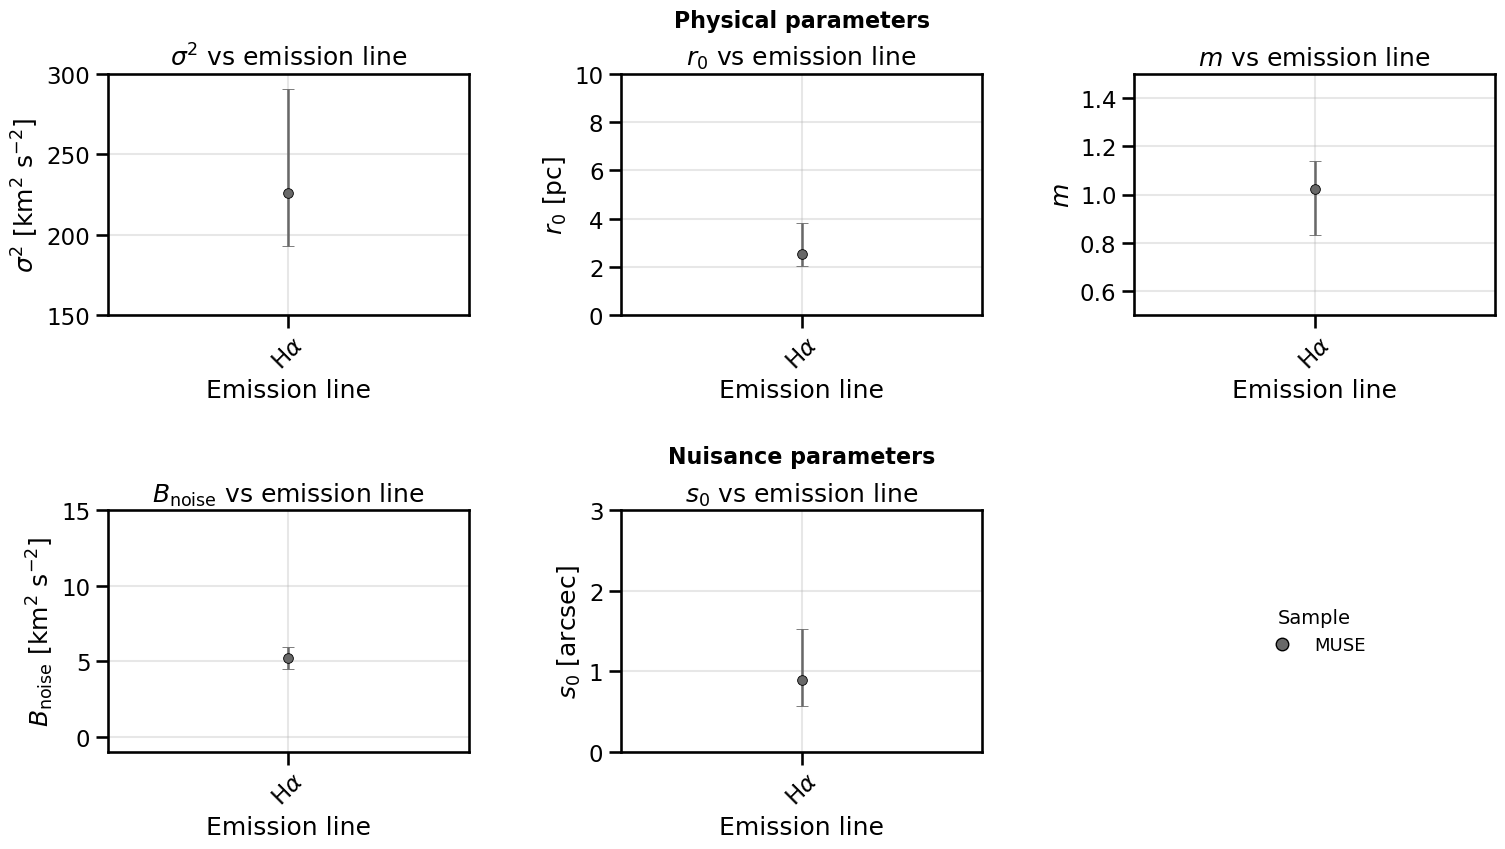

In [57]:
sample_selected = selected_results

LINE_LABELS = {
    "H": r"H$\alpha$",
}

PARAM_LABELS_ARCSEC = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}

fig_samples, axes_samples = ffa.plot_param_grid_lines_as_x(
    sample_selected,

    line_order=("H",),

    group_order=("MUSE",),
    group_key="group",

    line_labels=LINE_LABELS,
    param_labels=PARAM_LABELS_ARCSEC,

    param_ylims={
        "sig2": (150, 300),
        "r0": (0, 10),
        "m": (0.5, 1.5),
        "noise": (-1, 15),
        "s0": (0, 3),
    },

    row_titles=(
        "Physical parameters",
        "Nuisance parameters",
    ),

    row_title_fontsize=16,
    figsize=(15, 9),

    jitter=0.10,

    save=True,
    savepath=FIGS_DIR / "fit_fraction_average_by_sample.pdf",
)

for ax in axes_samples[:5]:
    ax.set_box_aspect(None)
    ax.set_aspect("auto")

fig_samples.subplots_adjust(
    left=0.065,
    right=0.99,
    wspace=0.42,
)

plt.show()

In [58]:
adopted_summary = (
    selected_table[
        [
            "group",
            "line",
            "fit_limits_used",
            "parameter",
            "value",
            "err_lower",
            "err_upper",
        ]
    ]
    .copy()
)

display(adopted_summary)

,group,line,fit_limits_used,parameter,value,err_lower,err_upper
0,MUSE,H,"(0.2, 0.3, 0.4)",sig2,225.710123,32.431691,65.061026
1,MUSE,H,"(0.2, 0.3, 0.4)",r0,2.529723,0.505398,1.287584
2,MUSE,H,"(0.2, 0.3, 0.4)",m,1.023771,0.189899,0.113757
3,MUSE,H,"(0.2, 0.3, 0.4)",noise,5.188290,0.673585,0.731041
4,MUSE,H,"(0.2, 0.3, 0.4)",s0,0.892114,0.329026,0.636786


Build the final adopted-parameter table

In [59]:
FINAL_PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

# Automatically determine the available groups
GROUP_ORDER = tuple(
    dict.fromkeys(selected_table["group"])
)

final_rows = []

for group in GROUP_ORDER:

    df_group = selected_table[
        selected_table["group"] == group
    ]

    if df_group.empty:
        continue

    row = {
        "group": group,
        "line": df_group["line"].iloc[0],
        "fit_limits_used": df_group["fit_limits_used"].iloc[0],
    }

    for param in FINAL_PARAMETERS:

        df_param = df_group[
            df_group["parameter"] == param
        ]

        if df_param.empty:
            continue

        values = df_param.iloc[0]

        row[param] = values["value"]
        row[f"{param}_err_lower"] = values["err_lower"]
        row[f"{param}_err_upper"] = values["err_upper"]

    final_rows.append(row)

final_table = pd.DataFrame(final_rows)

display(final_table)

,group,line,fit_limits_used,sig2,sig2_err_lower,sig2_err_upper,r0,r0_err_lower,r0_err_upper,m,m_err_lower,m_err_upper,noise,noise_err_lower,noise_err_upper,s0,s0_err_lower,s0_err_upper
0,MUSE,H,"(0.2, 0.3, 0.4)",225.710123,32.431691,65.061026,2.529723,0.505398,1.287584,1.023771,0.189899,0.113757,5.18829,0.673585,0.731041,0.892114,0.329026,0.636786


In [60]:
LATEX_LINE = "H"
LATEX_BIN = 0

latex_rows = []

for group in GROUP_ORDER:

    result_pc = ffa.get_fit_result(
        selected_results_pc,
        group=group,
        bin_level=LATEX_BIN,
        line=LATEX_LINE,
    )

    row = ffa.format_fit_summary_row(
        result_pc,
        fwhm=2.355,
        include_identifiers=True,
        line_labels=LINE_LABELS,
        row_terminator=True,
    )

    latex_rows.append(row)

print("\n".join(latex_rows))

MUSE & 0 & H$\alpha$ & 0.2,0.3,0.4 & 225.71\PM{65.06}{32.43} & 2.530\PM{1.288}{0.505} & 1.02\PM{0.11}{0.19} & 5.188\PM{0.731}{0.674} & <1.53 & 9.33 & <0.0622 & 0.019 \\


In [61]:
for group in GROUP_ORDER:

    result_pc = ffa.get_fit_result(
        selected_results_pc,
        group=group,
        bin_level=0,
        line="H",
    )

    print(f"\n--- {group} ---")

    ffa.print_fit_summary_row(
        result_pc,
        fwhm=2.355,
        include_identifiers=True,
        line_labels=LINE_LABELS,
        row_terminator=True,
    )


--- MUSE ---
MUSE & 0 & H$\alpha$ & 0.2,0.3,0.4 & 225.71\PM{65.06}{32.43} & 2.530\PM{1.288}{0.505} & 1.02\PM{0.11}{0.19} & 5.188\PM{0.731}{0.674} & <1.53 & 9.33 & <0.0622 & 0.019 \\


Export the adopted sample

In [62]:
OUTPUT_TABLE = ROOT / "fit_fraction_selected_results.csv"

final_table.to_csv(
    OUTPUT_TABLE,
    index=False,
)

print(f"Saved table to {OUTPUT_TABLE}")

Saved table to C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1\fit_fraction_selected_results.csv
